In [9]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, regularizers

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize images
X_train = X_train / 255.0
X_test = X_test / 255.0

In [10]:
# Model 1: Without regularization
m1 = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Model 2: L2 regularization
m2 = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation='relu',
                 kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(10, activation='softmax')
])

# Model 3: Dropout regularization
m3 = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

print("All three models created successfully!")

All three models created successfully!


In [11]:
#Compile and train models
histories = []

for model in [m1, m2, m3]:
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    h = model.fit(X_train, y_train, epochs=10,
                  validation_split=0.2, verbose=1)
    histories.append(h)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 68s 5ms/step - accuracy: 0.9179 - loss: 0.2857 - val_accuracy: 0.9541 - val_loss: 0.1595
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9633 - loss: 0.1266 - val_accuracy: 0.9643 - val_loss: 0.1181
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9738 - loss: 0.0875 - val_accuracy: 0.9682 - val_loss: 0.1066
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9799 - loss: 0.0652 - val_accuracy: 0.9722 - val_loss: 0.0939
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9850 - loss: 0.0496 - val_accuracy: 0.9729 - val_loss: 0.0866
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9878 - loss: 0.0392 - val_accuracy: 0.9706 - val_loss: 0.1051
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9907 - loss: 0.0310 - val_accuracy: 0.9728 - val_loss: 0.0938
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9926 - loss: 0.0247 -

In [13]:
#Evaluate test accuracy
for i, model in enumerate([m1, m2, m3], 1):
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    print(f"Model {i} Test Accuracy: {acc * 100:.2f}%")

Model 1 Test Accuracy: 97.48%
Model 2 Test Accuracy: 97.33%
Model 3 Test Accuracy: 97.65%


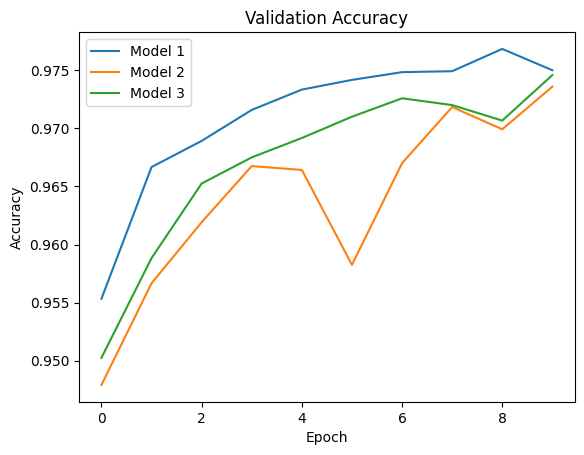

In [6]:
#Plot validation accuracy
for i, h in enumerate(histories, 1):
    plt.plot(h.history['val_accuracy'], label=f'Model {i}')

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

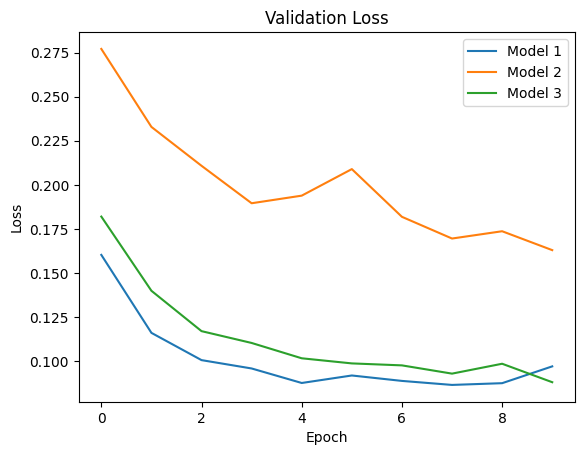

In [7]:
#Plot validation loss
for i, h in enumerate(histories, 1):
    plt.plot(h.history['val_loss'], label=f'Model {i}')

plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

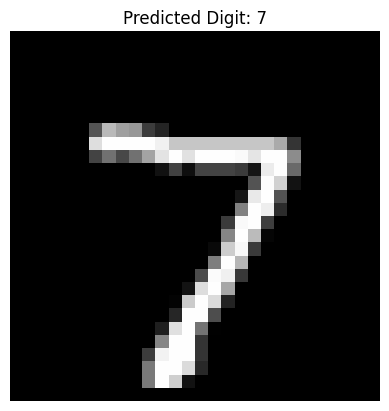

In [12]:
#Predict a digit
prediction = m3.predict(X_test[:1], verbose=0)

plt.imshow(X_test[0], cmap='gray')
plt.title(f"Predicted Digit: {prediction.argmax()}")
plt.axis('off')
plt.show()